## XGBoost 

### 1. Imports & configuration


In [1]:
import os, json, pickle, joblib, gc, time, random
import numpy as np
import pandas as pd
from itertools import combinations
from collections import Counter
from concurrent.futures import ProcessPoolExecutor, wait, FIRST_COMPLETED, as_completed
from PIL import Image

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    precision_score, recall_score, f1_score, accuracy_score,
    roc_auc_score, confusion_matrix,
    mean_absolute_error, mean_squared_error, r2_score
)
from scipy.stats import skew, kurtosis

import matplotlib.pyplot as plt
import seaborn as sns

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(it, **kwargs):
        return it

import warnings
warnings.filterwarnings("ignore")


In [ ]:
CKPT_DIR = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'

RFE_CKPT  = os.path.join(CKPT_DIR, 'ckpt_rfe_selection.pkl')
SAL_XGB_CKPT = os.path.join(CKPT_DIR, 'ckpt_xgb_saliency_feats.joblib')

print(f"CKPT_DIR = {CKPT_DIR}")

SEED    = 42
N_FOLDS = 5

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

print(f"SEED = {SEED} | N_FOLDS = {N_FOLDS}")


CKPT_DIR = /kaggle/working
SEED = 42 | N_FOLDS = 5


### 2. Locating the DREAM dataset


In [ ]:
KAGGLE_INPUT = '/kaggle/input'

def find_dream_root(base):
    best_root, best_n = None, 0
    for root, dirs, files in os.walk(base):
        n = 0
        for d in dirs:
            dp = os.path.join(root, d)
            try:
                n += sum(1 for f in os.listdir(dp)
                         if f.endswith('.json') and os.path.isfile(os.path.join(dp, f)))
            except OSError:
                pass
        if n > best_n:
            best_root, best_n = root, n
    if best_root is not None:
        print(f"Best candidate: {best_root} ({best_n} JSON files)")
    return best_root

if os.path.isdir(KAGGLE_INPUT):
    print("Environment detected : Kaggle")
    dream_root = find_dream_root(KAGGLE_INPUT)
    if dream_root is None:
        raise RuntimeError(
            "DREAM dataset not found in /kaggle/input/\n"
            "Check that the dataset has been added to the notebook via 'Add Data'."
        )
    extract_path = dream_root
    print(f"DREAM dataset found at: {extract_path}")
else:
    print("Environment detected : Colab / local")
    from google.colab import drive
    drive.mount('/content/drive')
    dream_path   = '/content/drive/MyDrive/Master_TSA/Datasets/Dream dataset/snd1156-1-1.zip'
    extract_path = '/content/DREAM'
    os.makedirs(extract_path, exist_ok=True)
    import zipfile
    with zipfile.ZipFile(dream_path, 'r') as z:
        z.extractall(extract_path)
    print("Complete extraction in :", extract_path)


Environment detected : Kaggle
Best candidate: /kaggle/input/datasets/rymjaballah/dream-dataset/snd1156-1-1/data/DREAM2020_SND1156-001-V1.0/DREAMdataset (3121 JSON files)
DREAM dataset found at: /kaggle/input/datasets/rymjaballah/dream-dataset/snd1156-1-1/data/DREAM2020_SND1156-001-V1.0/DREAMdataset


### 3. Utility functions + list of JSON files


In [4]:
def safe_first(obj):
    if isinstance(obj, list):
        return obj[0] if obj else {}
    return obj if obj is not None else {}

def assign_label(module, comm, inter):
    try:
        module = int(module)
    except (TypeError, ValueError):
        module = 1
    total = (comm or 0) + (inter or 0)
    cutoffs = {1: (7, 12), 2: (8, 12), 3: (7, 10)}
    asd_cut, aut_cut = cutoffs.get(module, (7, 12))
    if total >= aut_cut:
        return 'Autistic Disorder'
    elif total >= asd_cut:
        return 'ASD (AS, PDD)'
    return None

def to_float_array(lst):
    if not lst:
        return np.empty(0, dtype=float)
    return pd.to_numeric(pd.Series(lst), errors='coerce').to_numpy(dtype=float)

def build_xyz_array(d, keys):
    cols = [to_float_array(d.get(k, [])) for k in keys]
    n = max((len(c) for c in cols), default=0)
    if n == 0:
        return None
    out = np.full((n, len(keys)), np.nan)
    for i, c in enumerate(cols):
        out[:len(c), i] = c
    return out

all_json_files = []
for user_dir in sorted(os.listdir(extract_path)):
    user_path = os.path.join(extract_path, user_dir)
    if not os.path.isdir(user_path):
        continue
    for fname in sorted(os.listdir(user_path)):
        if fname.endswith(".json"):
            all_json_files.append(os.path.join(user_path, fname))

print(f"JSON files detected: {len(all_json_files)}")

MIN_EXPECTED_JSON = 50   # the full DREAM dataset has ~3000 files
if len(all_json_files) < MIN_EXPECTED_JSON:
    raise RuntimeError(
        f"Only {len(all_json_files)} JSON files found in '{extract_path}'. "
        "Wrong folder or dataset not attached. Check /kaggle/input (Add Data)."
    )


JSON files detected: 3121


### 4. Train/test split



In [ ]:
if os.path.exists(RFE_CKPT):
    print(f"Checkpoint found: {RFE_CKPT} -> loading (no recomputation).")
    with open(RFE_CKPT, 'rb') as f:
        _ck = pickle.load(f)
    le               = _ck['le']
    train_pids       = _ck['train_pids']
    test_pids_unique = _ck['test_pids_unique']

else:
    print("No RFE checkpoint found -> launching Part A (extraction + split + RFE).")
    print("This step can take a while the first time (it reads all the JSON files).")

    #Extraction constants 
    SEGMENT_SIZE = 25
    JOINTS = ['Head', 'ShoulderCenter', 'ShoulderLeft', 'ShoulderRight',
              'ElbowLeft', 'ElbowRight', 'WristLeft', 'WristRight',
              'HandLeft', 'HandRight']
    JOINT_MAP_RAW = {
        'head':           'Head',
        'sholder_center': 'ShoulderCenter',
        'sholder_left':   'ShoulderLeft',
        'sholder_right':  'ShoulderRight',
        'elbow_left':     'ElbowLeft',
        'elbow_right':    'ElbowRight',
        'wrist_left':     'WristLeft',
        'wrist_right':    'WristRight',
        'hand_left':      'HandLeft',
        'hand_right':     'HandRight',
    }
    ANGLE_TRIPLETS = [
        ('Head',          'ShoulderCenter', 'ShoulderLeft'),
        ('Head',          'ShoulderCenter', 'ShoulderRight'),
        ('ShoulderLeft',  'ShoulderCenter', 'ShoulderRight'),
        ('ShoulderCenter','ShoulderLeft',   'ElbowLeft'),
        ('ShoulderCenter','ShoulderRight',  'ElbowRight'),
        ('ShoulderLeft',  'ElbowLeft',      'WristLeft'),
        ('ShoulderRight', 'ElbowRight',     'WristRight'),
        ('ElbowLeft',     'WristLeft',      'HandLeft'),
        ('ElbowRight',    'WristRight',     'HandRight'),
    ]

    N_WORKERS = max(1, min((os.cpu_count() or 2) - 1, 8))
    MAX_IN_FLIGHT = N_WORKERS * 4
    CHECKPOINT_EVERY = 200
    CHECKPOINT_SECONDS = 180
    CHECKPOINT_PKL = os.path.join(CKPT_DIR, 'feat_checkpoint.pkl')

    def euclidean_dist(A, B):
        return float(np.sqrt(np.sum((A - B) ** 2)))

    def angle_between(P1, P2, P3):
        v1 = P1 - P2; v2 = P3 - P2
        cos_a = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2) + 1e-9)
        return float(np.degrees(np.arccos(np.clip(cos_a, -1, 1))))

    def extract_features_arrays(seg_arrays, gaze_arrays, normative):
        feats = {}
        means = {j: seg_arrays[j].mean(axis=0) for j in JOINTS}
        for jA, jB in combinations(JOINTS, 2):
            feats[f'{jA}_{jB}_dist'] = euclidean_dist(means[jA], means[jB])
        for P1n, P2n, P3n in ANGLE_TRIPLETS:
            feats[f'{P1n}_{P2n}_{P3n}_angle'] = angle_between(means[P1n], means[P2n], means[P3n])
        vectors = {}
        for name in ['head', 'eye']:
            G_arr = gaze_arrays.get(name)
            if G_arr is not None and G_arr.shape[0] > 0:
                G = G_arr.mean(axis=0)
                mag = np.linalg.norm(G) + 1e-9
                feats[f'{name}_alpha'] = float(np.degrees(np.arccos(np.clip(G[0]/mag, -1, 1))))
                feats[f'{name}_beta']  = float(np.degrees(np.arccos(np.clip(G[1]/mag, -1, 1))))
                feats[f'{name}_gamma'] = float(np.degrees(np.arccos(np.clip(G[2]/mag, -1, 1))))
                vectors[name] = G
            else:
                feats[f'{name}_alpha'] = feats[f'{name}_beta'] = feats[f'{name}_gamma'] = np.nan
        if 'head' in vectors and 'eye' in vectors:
            H, E = vectors['head'], vectors['eye']
            H_mag = np.linalg.norm(H) + 1e-9
            E_mag = np.linalg.norm(E) + 1e-9
            cos_t = np.dot(E, H) / (E_mag * H_mag)
            theta = np.arccos(np.clip(cos_t, -1, 1))
            feats['gaze_angle_EH'] = float(np.degrees(theta))
            feats['gaze_zone_phi'] = float(np.degrees(np.arctan2(H_mag*np.sin(theta), E_mag+H_mag*np.cos(theta))))
        else:
            feats['gaze_angle_EH'] = feats['gaze_zone_phi'] = np.nan
        for j in JOINTS:
            for ax_i, ax in enumerate(['x','y','z']):
                col = f'skeleton_{j.lower()}_{ax}'
                feats[f'{col}_std'] = float(seg_arrays[j][:, ax_i].std())
        for name in ['head', 'eye']:
            G_arr = gaze_arrays.get(name)
            for ax_i, ax in enumerate(['rx','ry','rz']):
                col = f'{name}_gaze_{ax}'
                feats[f'{col}_std'] = float(G_arr[:, ax_i].std()) if G_arr is not None else np.nan
        feats.update(normative)
        return feats

    def process_json_file(fpath):
        with open(fpath) as f:
            data = json.load(f)
        p         = safe_first(data.get('participant', {}))
        ados      = data.get('ados', {})
        ados_data = ados.get('preTest', {}) if isinstance(ados, dict) else {}
        t         = data.get('task', {}) if isinstance(data.get('task'), dict) else {}
        comm   = ados_data.get('communication')
        inter  = ados_data.get('interaction')
        module = ados_data.get('module')
        label  = assign_label(module, comm, inter)
        if label is None:
            return []
        pid        = p.get('id', p.get('child_id'))
        age_months = p.get('ageInMonths', p.get('age_months'))
        gender_raw = str(p.get('gender', 'unknown'))
        cond_raw   = data.get('condition', p.get('condition', 'SHT'))
        difficulty_raw = t.get('difficultyLevel', t.get('task_ability', 0))
        ability_raw= str(t.get('ability', t.get('task_ability', 'unknown')))
        ados_score = (comm or 0) + (inter or 0)
        skel = data.get('skeleton', {})
        hg   = data.get('head_gaze', {})
        eg   = data.get('eye_gaze',  {})
        joint_series = {}
        for raw_key, canon in JOINT_MAP_RAW.items():
            joint = skel.get(raw_key, {})
            joint_series[canon] = build_xyz_array(joint, ('x', 'y', 'z')) if isinstance(joint, dict) else None
        gaze_series = {
            'head': build_xyz_array(hg, ('rx', 'ry', 'rz')),
            'eye':  build_xyz_array(eg, ('rx', 'ry', 'rz')),
        }
        lengths = [a.shape[0] for a in joint_series.values() if a is not None]
        lengths += [a.shape[0] for a in gaze_series.values() if a is not None]
        if not lengths:
            return []
        n_frames = max(lengths)
        n_segs = n_frames // SEGMENT_SIZE
        if n_segs == 0:
            return []
        feats_list = []
        for i in range(n_segs):
            s, e = i * SEGMENT_SIZE, (i + 1) * SEGMENT_SIZE
            seg_arrays = {}
            for j in JOINTS:
                arr = joint_series[j]
                if arr is not None and s < arr.shape[0]:
                    seg_arrays[j] = arr[s:min(e, arr.shape[0])]
                    if len(seg_arrays[j]) < SEGMENT_SIZE:
                        pad = np.full((SEGMENT_SIZE - len(seg_arrays[j]), 3), np.nan)
                        seg_arrays[j] = np.vstack([seg_arrays[j], pad])
                else:
                    seg_arrays[j] = np.full((SEGMENT_SIZE, 3), np.nan)
            seg_gaze = {}
            for name, arr in gaze_series.items():
                if arr is not None and s < arr.shape[0]:
                    sliced = arr[s:min(e, arr.shape[0])]
                    if len(sliced) < SEGMENT_SIZE:
                        pad = np.full((SEGMENT_SIZE - len(sliced), 3), np.nan)
                        sliced = np.vstack([sliced, pad])
                    seg_gaze[name] = sliced
                else:
                    seg_gaze[name] = None
            normative = {
                'participant_ageInMonths': age_months,
                'age_group':    0,
                'gender':       gender_raw,
                'task_ability': ability_raw,
                'task_difficulty': difficulty_raw,
            }
            feats = extract_features_arrays(seg_arrays, seg_gaze, normative)
            feats['participant_id'] = pid
            feats['label']          = label
            feats['ados_score']     = ados_score
            feats['age_months']     = age_months
            feats['condition']      = cond_raw
            feats_list.append(feats)
        return feats_list

    processed_set = set()
    all_feats = []
    if os.path.exists(CHECKPOINT_PKL):
        with open(CHECKPOINT_PKL, 'rb') as f:
            ck = pickle.load(f)
        processed_set = ck.get('processed', set())
        all_feats     = ck.get('feats', [])
        print(f"Extraction checkpoint found -> {len(processed_set)} files already processed.")

    remaining_files = [f for f in all_json_files if f not in processed_set]
    print(f"Remaining files to process: {len(remaining_files)}")

    def save_checkpoint():
        with open(CHECKPOINT_PKL, 'wb') as f:
            pickle.dump({'feats': all_feats, 'processed': processed_set}, f)

    n_done = len(processed_set)
    t0 = time.time()

    if remaining_files:
        file_iter = iter(remaining_files)
        last_ckpt_time = time.time()
        with ProcessPoolExecutor(max_workers=N_WORKERS) as ex:
            futures = {}
            for _ in range(min(MAX_IN_FLIGHT, len(remaining_files))):
                fp = next(file_iter)
                futures[ex.submit(process_json_file, fp)] = fp
            pbar = tqdm(total=len(remaining_files), desc="Extracting features")
            while futures:
                done, _ = wait(futures, return_when=FIRST_COMPLETED)
                for fut in done:
                    fp = futures.pop(fut)
                    try:
                        feats = fut.result()
                        all_feats.extend(feats)
                    except Exception as e:
                        pass
                    processed_set.add(fp)
                    n_done += 1
                    pbar.update(1)
                    try:
                        nf = next(file_iter)
                        futures[ex.submit(process_json_file, nf)] = nf
                    except StopIteration:
                        pass
                    now = time.time()
                    if n_done % CHECKPOINT_EVERY == 0 or (now - last_ckpt_time) > CHECKPOINT_SECONDS:
                        save_checkpoint()
                        last_ckpt_time = now
            pbar.close()
        save_checkpoint()

    feat_df = pd.DataFrame(all_feats)
    gc.collect()
    feat_df['gender']       = LabelEncoder().fit_transform(feat_df['gender'].astype(str))
    feat_df['task_ability'] = LabelEncoder().fit_transform(feat_df['task_ability'].astype(str))
    feat_df['age_group']    = pd.cut(feat_df['age_months'], bins=5, labels=[0,1,2,3,4]).astype(int)
    feat_df['participant_ageInMonths'] = feat_df['age_months']
    print(f"Total segments: {len(feat_df)} | Participants: {feat_df['participant_id'].nunique()}")

    #Train/test split + RFE 
    EXCLUDE = {'participant_id', 'label', 'ados_score', 'age_months', 'condition'}
    FEATURE_COLS = [c for c in feat_df.columns if c not in EXCLUDE]
    X_raw = feat_df[FEATURE_COLS].copy()
    y_clf_raw = feat_df['label']
    y_reg_raw = feat_df['ados_score']

    X_raw = X_raw.dropna(axis=1, how='all')
    FEATURE_COLS = list(X_raw.columns)

    nan_rate_by_pid = (
        feat_df.assign(**{c: X_raw[c] for c in FEATURE_COLS})
               .groupby('participant_id')[FEATURE_COLS]
               .apply(lambda g: g.isna().mean().mean())
    )
    nan_rate_sorted = nan_rate_by_pid.sort_values(ascending=False)
    N_TO_EXCLUDE = 7
    excluded_pids = nan_rate_sorted.head(N_TO_EXCLUDE).index.tolist()
    print(f"Excluded participants (too many NaN): {excluded_pids}")

    keep_mask = ~feat_df['participant_id'].isin(excluded_pids).values
    feat_df_clean = feat_df.loc[keep_mask].reset_index(drop=True)
    X_raw          = X_raw.loc[keep_mask].reset_index(drop=True)
    y_clf_raw      = y_clf_raw.loc[keep_mask].reset_index(drop=True)
    y_reg_raw      = y_reg_raw.loc[keep_mask].reset_index(drop=True)

    participant_label = feat_df_clean.groupby('participant_id')['label'].agg(
        lambda s: s.value_counts().idxmax()
    )
    train_ids, test_ids = train_test_split(
        participant_label.index.to_numpy(),
        test_size=8,
        stratify=participant_label.values,
        random_state=SEED
    )
    print(f"Train: {len(train_ids)} participants | Test: {len(test_ids)} participants")

    train_mask = feat_df_clean['participant_id'].isin(train_ids).values
    test_mask  = feat_df_clean['participant_id'].isin(test_ids).values

    train_medians = X_raw[train_mask].median(numeric_only=True)
    X_raw = X_raw.fillna(train_medians)

    le = LabelEncoder()
    y_clf = le.fit_transform(y_clf_raw)
    y_reg = y_reg_raw.values

    X_train_raw = X_raw.values[train_mask]
    X_test_raw  = X_raw.values[test_mask]
    y_train_clf = y_clf[train_mask]
    y_test_clf  = y_clf[test_mask]
    y_train_reg = y_reg[train_mask]
    y_test_reg  = y_reg[test_mask]

    train_pids = feat_df_clean['participant_id'].values[train_mask]
    test_pids_unique = sorted(test_ids.tolist())

    rf_base = RandomForestClassifier(n_estimators=50, criterion='entropy', random_state=SEED, n_jobs=-1)
    rfe = RFE(estimator=rf_base, n_features_to_select=53, step=5)
    rfe.fit(X_train_raw, y_train_clf)

    X_train_sel = rfe.transform(X_train_raw)
    X_test_sel  = rfe.transform(X_test_raw)
    selected_features = [FEATURE_COLS[i] for i, s in enumerate(rfe.support_) if s]

    with open(RFE_CKPT, 'wb') as f:
        pickle.dump({
            'FEATURE_COLS': FEATURE_COLS,
            'X_train_sel': X_train_sel, 'X_test_sel': X_test_sel,
            'y_train_clf': y_train_clf, 'y_test_clf': y_test_clf,
            'y_train_reg': y_train_reg, 'y_test_reg': y_test_reg,
            'le': le, 'selected_features': selected_features,
            'train_pids': train_pids,
            'test_pids_unique': test_pids_unique,
        }, f)
    print(f"RFE checkpoint saved -> {RFE_CKPT}")

train_pid_set = set(train_pids.tolist() if hasattr(train_pids, 'tolist') else train_pids)
test_pid_set  = set(test_pids_unique)

print(f"Train participants: {len(train_pid_set)} | Test participants: {len(test_pid_set)}")
print(f"Classes: {le.classes_}")


No RFE checkpoint found -> launching Part A (extraction + split + RFE).
This step can take a while the first time (it reads all the JSON files).
Remaining files to process: 3121


Extracting features:   0%|          | 0/3121 [00:00<?, ?it/s]

Total segments: 1012441 | Participants: 61
Excluded participants (too many NaN): [31, 14, 15, 32, 44, 50, 30]
Train: 46 participants | Test: 8 participants
RFE checkpoint saved -> /kaggle/working/ckpt_rfe_selection.pkl
Train participants: 46 | Test participants: 8
Classes: ['ASD (AS, PDD)' 'Autistic Disorder']


### 5. Viewframes + gaze projection geometry


In [6]:
VIEWFRAMES = {
    'front':  {'center': np.array([0.0, 0.0, 700.0]),
               'width_axis': np.array([1.0, 0.0, 0.0]), 'height_axis': np.array([0.0, 1.0, 0.0]),
               'width': 800.0, 'height': 600.0},
    'left':   {'center': np.array([-450.0, 0.0, 0.0]),
               'width_axis': np.array([0.0, 0.0, 1.0]), 'height_axis': np.array([0.0, 1.0, 0.0]),
               'width': 600.0, 'height': 600.0},
    'right':  {'center': np.array([450.0, 0.0, 0.0]),
               'width_axis': np.array([0.0, 0.0, 1.0]), 'height_axis': np.array([0.0, 1.0, 0.0]),
               'width': 600.0, 'height': 600.0},
    'top':    {'center': np.array([0.0, 450.0, 0.0]),
               'width_axis': np.array([1.0, 0.0, 0.0]), 'height_axis': np.array([0.0, 0.0, 1.0]),
               'width': 800.0, 'height': 600.0},
    'bottom': {'center': np.array([0.0, -300.0, 0.0]),
               'width_axis': np.array([1.0, 0.0, 0.0]), 'height_axis': np.array([0.0, 0.0, 1.0]),
               'width': 800.0, 'height': 600.0},
}

def ray_plane_intersection(Pv, D, vf):
    width_axis, height_axis = vf['width_axis'], vf['height_axis']
    width, height, center = vf['width'], vf['height'], vf['center']
    corner = center - (width / 2.0) * width_axis - (height / 2.0) * height_axis
    E1 = width_axis * width
    E2 = height_axis * height
    N = np.cross(E1, E2)
    N = N / np.linalg.norm(N)
    denom = D @ N
    if abs(denom) < 1e-9:
        return None
    t = ((corner - Pv) @ N) / denom
    if t <= 0:
        return None
    Pi = Pv + t * D
    rel = Pi - corner
    u_proj = rel @ width_axis
    v_proj = rel @ height_axis
    if 0.0 <= u_proj <= width and 0.0 <= v_proj <= height:
        return (u_proj - width / 2.0, v_proj - height / 2.0)
    return None

def assign_viewframe(Pv, D):
    for name in ['front', 'left', 'right', 'top', 'bottom']:
        res = ray_plane_intersection(Pv, D, VIEWFRAMES[name])
        if res is not None:
            return name, res[0], res[1]
    return None, None, None


### 6. Participant-level evaluation


In [7]:
def evaluate_at_participant_level(probs, y_true_seg, pids_seg, test_pid_set, label_names):
    prob_by_pid, true_by_pid = {}, {}
    for pid in test_pid_set:
        m = np.array(pids_seg) == pid
        if m.sum() == 0:
            continue
        prob_by_pid[pid] = probs[m].mean(axis=0)
        true_by_pid[pid] = Counter(y_true_seg[m]).most_common(1)[0][0]

    pids_sorted = sorted(prob_by_pid.keys())
    y_true_p = [true_by_pid[pid] for pid in pids_sorted]
    y_pred_p = [int(np.argmax(prob_by_pid[pid])) for pid in pids_sorted]

    metrics = {
        'precision': precision_score(y_true_p, y_pred_p, average="macro", zero_division=0) * 100,
        'recall':    recall_score(y_true_p, y_pred_p, average="macro", zero_division=0) * 100,
        'f1':        f1_score(y_true_p, y_pred_p, average="macro", zero_division=0) * 100,
        'accuracy':  accuracy_score(y_true_p, y_pred_p) * 100,
        'n_participants': len(pids_sorted),
    }
    cm = confusion_matrix(y_true_p, y_pred_p)
    return metrics, cm, y_true_p, y_pred_p


def get_participant_level_probs(probs, pids_seg, test_pid_set):
    prob_by_pid = {}
    for pid in test_pid_set:
        m = np.array(pids_seg) == pid
        if m.sum() == 0:
            continue
        prob_by_pid[pid] = probs[m].mean(axis=0)
    pids_sorted = sorted(prob_by_pid.keys())
    y_prob_p = np.stack([prob_by_pid[pid] for pid in pids_sorted])
    return y_prob_p, pids_sorted


### 7. Generating the saliency maps


In [8]:
IMG_SIZE = 224

def compute_bandwidth(pts):
    n = len(pts)
    mean = pts.mean(axis=0)
    d = np.linalg.norm(pts - mean, axis=1)
    SD = np.sqrt(np.mean(d ** 2))
    Dm = np.median(d)
    SB = 0.9 * min(SD, np.sqrt(1.0 / np.log(2)) * Dm) * (n ** (-0.2))
    return max(SB, 1e-3)

def gaussian_kernel_2d(x):
    return (1.0 / (2.0 * np.pi)) * np.exp(-0.5 * np.sum(x ** 2, axis=-1))

def render_saliency_panel(points, half_u, half_v, grid_size=128):
    if len(points) < 5:
        return None
    pts = np.array(points)
    h = compute_bandwidth(pts)
    n = len(pts)
    uu, vv = np.meshgrid(
        np.linspace(-half_u, half_u, grid_size),
        np.linspace(-half_v, half_v, grid_size)
    )
    grid = np.stack([uu.ravel(), vv.ravel()], axis=-1)
    diffs = (grid[:, None, :] - pts[None, :, :]) / h
    kernel_vals = gaussian_kernel_2d(diffs)
    density = kernel_vals.sum(axis=1) / (n * h ** 2)
    density = density.reshape(grid_size, grid_size)
    density = (density - density.min()) / (density.max() - density.min() + 1e-9)
    return density

def build_multichannel_saliency_image(points_by_vf, img_size=IMG_SIZE, grid_size=128):
    def panel_or_zeros(name):
        p = render_saliency_panel(points_by_vf[name],
                                   VIEWFRAMES[name]['width'] / 2.0,
                                   VIEWFRAMES[name]['height'] / 2.0,
                                   grid_size=grid_size)
        return p if p is not None else np.zeros((grid_size, grid_size))

    front = panel_or_zeros('front')
    left, right = panel_or_zeros('left'), panel_or_zeros('right')
    top, bottom = panel_or_zeros('top'), panel_or_zeros('bottom')

    R = front
    G = (left + right) / 2.0
    B = (top + bottom) / 2.0

    rgb = np.stack([R, G, B], axis=-1)
    rgb_img = (rgb * 255).astype(np.uint8)
    rgb_img = np.array(Image.fromarray(rgb_img).resize((img_size, img_size)))
    return rgb_img


In [9]:
N_CHUNKS_VGG = 4

def process_json_file_gaze_chunks_vgg(fpath, n_chunks=N_CHUNKS_VGG, img_size=IMG_SIZE):
    with open(fpath) as f:
        data = json.load(f)

    p = safe_first(data.get('participant', {}))
    ados = data.get('ados', {})
    ados_data = ados.get('preTest', {}) if isinstance(ados, dict) else {}
    comm, inter, module = ados_data.get('communication'), ados_data.get('interaction'), ados_data.get('module')
    label = assign_label(module, comm, inter)
    if label is None:
        return []

    pid = p.get('id', p.get('child_id'))
    skel = data.get('skeleton', {})
    eg = data.get('eye_gaze', {})

    head_arr = build_xyz_array(skel.get('head', {}), ('x', 'y', 'z'))
    eye_arr = build_xyz_array(eg, ('rx', 'ry', 'rz'))
    if head_arr is None or eye_arr is None:
        return []

    n = min(len(head_arr), len(eye_arr))
    if n == 0:
        return []
    head_arr, eye_arr = head_arr[:n], eye_arr[:n]
    valid = ~np.isnan(head_arr).any(axis=1) & ~np.isnan(eye_arr).any(axis=1)
    head_v, eye_v = head_arr[valid], eye_arr[valid]
    n_valid = len(head_v)
    if n_valid < 5 * n_chunks:
        return []

    bounds = np.linspace(0, n_valid, n_chunks + 1).astype(int)
    results = []
    for c in range(n_chunks):
        h_c, e_c = head_v[bounds[c]:bounds[c+1]], eye_v[bounds[c]:bounds[c+1]]
        points_by_vf = {name: [] for name in VIEWFRAMES}
        for Pv, D_raw in zip(h_c, e_c):
            norm = np.linalg.norm(D_raw)
            if norm < 1e-9:
                continue
            D = D_raw / norm
            name, u, v = assign_viewframe(Pv, D)
            if name is not None:
                points_by_vf[name].append((u, v))
        img = build_multichannel_saliency_image(points_by_vf, img_size=img_size)
        results.append({'participant_id': pid, 'label': label, 'image': img, 'chunk': c})
    return results

N_WORKERS = max(1, min((os.cpu_count() or 2) - 1, 8))
VGG_CHUNKS_CKPT = os.path.join(CKPT_DIR, 'ckpt_vgg_chunks_v1.pkl')

if os.path.exists(VGG_CHUNKS_CKPT):
    print(f"Checkpoint found -> {VGG_CHUNKS_CKPT} : loading.")
    with open(VGG_CHUNKS_CKPT, 'rb') as f:
        vgg_chunk_records = pickle.load(f)
else:
    vgg_chunk_records = []
    with ProcessPoolExecutor(max_workers=N_WORKERS) as ex:
        futures = {ex.submit(process_json_file_gaze_chunks_vgg, fp): fp for fp in all_json_files}
        for fut in tqdm(as_completed(futures), total=len(futures), desc="Saliency chunks"):
            vgg_chunk_records.extend(fut.result())
    with open(VGG_CHUNKS_CKPT, 'wb') as f:
        pickle.dump(vgg_chunk_records, f)
    print(f"Checkpoint saved -> {VGG_CHUNKS_CKPT}")

print(f"Total images generated: {len(vgg_chunk_records)}")

sal_imgs   = np.stack([r['image'] for r in vgg_chunk_records])
sal_labels = np.array([r['label'] for r in vgg_chunk_records])
sal_pids   = np.array([r['participant_id'] for r in vgg_chunk_records])

y_sal_enc = le.transform(sal_labels)
idx_train = [i for i, pid in enumerate(sal_pids) if pid in train_pid_set]
idx_test  = [i for i, pid in enumerate(sal_pids) if pid in test_pid_set]

y_sal_train = y_sal_enc[idx_train]
y_sal_test  = y_sal_enc[idx_test]

print(f"Train images: {len(idx_train)} | Test images: {len(idx_test)}")


Saliency chunks:   0%|          | 0/3121 [00:00<?, ?it/s]

Checkpoint saved -> /kaggle/working/ckpt_vgg_chunks_v1.pkl
Total images generated: 12148
Train images: 9288 | Test images: 1860


### 8. Handcrafted features (30 features/image)


In [10]:
def extract_saliency_handcrafted_features(img):
    h, w = img.shape[0], img.shape[1]
    yy, xx = np.mgrid[0:h, 0:w]
    feats = []
    for c in range(3):
        chan = img[:, :, c].astype(np.float64)
        flat = chan.ravel()
        total = flat.sum()

        mean_v, std_v = flat.mean(), flat.std()
        skew_v, kurt_v = skew(flat), kurtosis(flat)
        min_v, max_v = flat.min(), flat.max()
        energy = np.sum((flat / 255.0) ** 2) / flat.size

        hist, _ = np.histogram(flat, bins=32, range=(0, 255), density=True)
        hist = hist + 1e-12
        entropy = -np.sum(hist * np.log(hist))

        if total > 1e-9:
            cx = (xx.ravel() * flat).sum() / total
            cy = (yy.ravel() * flat).sum() / total
        else:
            cx, cy = w / 2.0, h / 2.0

        feats.extend([mean_v, std_v, skew_v, kurt_v, min_v, max_v, energy, entropy, cx, cy])
    return np.array(feats, dtype=np.float64)

SAL_FEAT_CKPT = os.path.join(CKPT_DIR, 'ckpt_saliency_handcrafted_feats.pkl')

if os.path.exists(SAL_FEAT_CKPT):
    print(f"Checkpoint found: {SAL_FEAT_CKPT} -> loading.")
    with open(SAL_FEAT_CKPT, 'rb') as f:
        X_sal_feat_all = pickle.load(f)
else:
    X_sal_feat_all = np.stack([
        extract_saliency_handcrafted_features(img)
        for img in tqdm(sal_imgs, desc="Extracting handcrafted features")
    ])
    with open(SAL_FEAT_CKPT, 'wb') as f:
        pickle.dump(X_sal_feat_all, f)
    print(f"Features saved -> {SAL_FEAT_CKPT}")

X_sal_feat_train = X_sal_feat_all[idx_train]
X_sal_feat_test  = X_sal_feat_all[idx_test]
print(f"Handcrafted features shape: {X_sal_feat_all.shape}")


Extracting handcrafted features:   0%|          | 0/12148 [00:00<?, ?it/s]

Features saved -> /kaggle/working/ckpt_saliency_handcrafted_feats.pkl
Handcrafted features shape: (12148, 30)


### 9. XGBoost 



In [ ]:
try:
    import xgboost as xgb
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost", "--quiet"])
    import xgboost as xgb

cv_pid_set = train_pid_set | test_pid_set
pid_label = {}
for pid in cv_pid_set:
    m = sal_pids == pid
    if m.any():
        pid_label[pid] = Counter(y_sal_enc[m]).most_common(1)[0][0]

cv_pids  = np.array(sorted(pid_label))
cv_pid_y = np.array([pid_label[p] for p in cv_pids])
n_classes = len(le.classes_)

min_class = np.bincount(cv_pid_y, minlength=n_classes).min()
if min_class < N_FOLDS:
    raise ValueError(f"Smallest class has only {min_class} participants < N_FOLDS={N_FOLDS}.")
print(f"CV pool: {len(cv_pids)} participants | class counts: {np.bincount(cv_pid_y).tolist()}")

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

fold_rows = []
cm_total  = np.zeros((n_classes, n_classes), dtype=int)

for fold, (tr_i, te_i) in enumerate(skf.split(cv_pids, cv_pid_y), start=1):
    tr_mask = np.isin(sal_pids, cv_pids[tr_i])
    te_mask = np.isin(sal_pids, cv_pids[te_i])
    fold_test_pids = set(cv_pids[te_i].tolist())

    X_tr, y_tr = X_sal_feat_all[tr_mask], y_sal_enc[tr_mask]
    X_te, y_te = X_sal_feat_all[te_mask], y_sal_enc[te_mask]
    pids_te    = sal_pids[te_mask]

    counts = pd.Series(y_tr).value_counts().to_dict()
    scale_pos_weight = counts.get(0, 1) / counts.get(1, 1)

    model = xgb.XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        random_state=SEED, n_jobs=-1, eval_metric='logloss'
    )
    model.fit(X_tr, y_tr)
    prob = model.predict_proba(X_te)

    m_p, _, y_true_p, y_pred_p = evaluate_at_participant_level(
        prob, y_te, pids_te, fold_test_pids, le.classes_
    )
    y_prob_p, _ = get_participant_level_probs(prob, pids_te, fold_test_pids)
    if n_classes == 2:
        auc = roc_auc_score(y_true_p, y_prob_p[:, 1])
    else:
        auc = roc_auc_score(y_true_p, y_prob_p, multi_class="ovr", average="micro")
    cm_total += confusion_matrix(y_true_p, y_pred_p, labels=np.arange(n_classes))

    y_prob_img = prob[:, 1]
    mse_img = mean_squared_error(y_te, y_prob_img)

    y_prob_part = y_prob_p[:, 1]
    mse_part = mean_squared_error(y_true_p, y_prob_part)

    fold_rows.append({
        'fold': fold,
        'n_test_participants': m_p['n_participants'],
        'n_test_images': int(te_mask.sum()),
        # participant-level classification
        'precision': m_p['precision'], 'recall': m_p['recall'],
        'f1': m_p['f1'], 'accuracy': m_p['accuracy'], 'auc': auc,
        # image-level regression
        'mae_img': mean_absolute_error(y_te, y_prob_img), 'mse_img': mse_img,
        'rmse_img': np.sqrt(mse_img), 'r2_img': r2_score(y_te, y_prob_img),
        # participant-level regression
        'mae_part': mean_absolute_error(y_true_p, y_prob_part), 'mse_part': mse_part,
        'rmse_part': np.sqrt(mse_part), 'r2_part': r2_score(y_true_p, y_prob_part),
    })
    print(f"Fold {fold}/{N_FOLDS} | test participants: {m_p['n_participants']} | "
          f"acc = {m_p['accuracy']:.2f} | f1 = {m_p['f1']:.2f} | auc = {auc:.4f}")

cv_df = pd.DataFrame(fold_rows).set_index('fold')
cv_df.round(4)


CV pool: 54 participants | class counts: [13, 41]
Fold 1/5 | test participants: 11 | acc = 72.73 | f1 = 61.18 | auc = 0.5556
Fold 2/5 | test participants: 11 | acc = 54.55 | f1 = 52.99 | auc = 0.7083
Fold 3/5 | test participants: 11 | acc = 63.64 | f1 = 54.17 | auc = 0.7500
Fold 4/5 | test participants: 11 | acc = 63.64 | f1 = 54.17 | auc = 0.6667
Fold 5/5 | test participants: 10 | acc = 30.00 | f1 = 23.08 | auc = 0.3750


,n_test_participants,n_test_images,precision,recall,f1,accuracy,auc,mae_img,mse_img,rmse_img,r2_img,mae_part,mse_part,rmse_part,r2_part
fold,,,,,,,,,,,,,,,
1,11,2072,60.4167,63.8889,61.1765,72.7273,0.5556,0.4481,0.2367,0.4865,-0.5428,0.4604,0.2191,0.4681,-0.4731
2,11,2292,56.6667,58.3333,52.9915,54.5455,0.7083,0.4909,0.2598,0.5097,-0.4423,0.4902,0.2414,0.4913,-0.2170
3,11,2424,54.1667,54.1667,54.1667,63.6364,0.7500,0.4631,0.2384,0.4882,-0.3351,0.4628,0.2180,0.4669,-0.0990
4,11,2292,54.1667,54.1667,54.1667,63.6364,0.6667,0.4587,0.2326,0.4823,-0.1602,0.4615,0.2183,0.4672,-0.1004
5,10,2068,30.0000,18.7500,23.0769,30.0000,0.3750,0.5021,0.2798,0.5289,-0.5518,0.4806,0.2405,0.4904,-0.5030


XGBoost — 5-fold CV (seed=42) — mean ± std over folds

=== PARTICIPANT level — classification ===
Precision (%) : 51.08 ± 12.06
Recall    (%) : 49.86 ± 17.84
F1        (%) : 49.12 ± 14.91
Accuracy  (%) : 56.91 ± 16.36
AUC           : 0.6111 ± 0.1506

=== IMAGE level (per chunk) — regression on P(class 1) ===
MAE  : 0.4726 ± 0.0228
MSE  : 0.2494 ± 0.0200
RMSE : 0.4991 ± 0.0198
R2   : -0.4065 ± 0.1634

=== PARTICIPANT level — regression on mean P(class 1) ===
MAE  : 0.4711 ± 0.0135
MSE  : 0.2274 ± 0.0123
RMSE : 0.4768 ± 0.0129
R2   : -0.2785 ± 0.1975


,mean,std
precision,51.0833,12.0603
recall,49.8611,17.8433
f1,49.1156,14.9125
accuracy,56.9091,16.3586
auc,0.6111,0.1506
mae_img,0.4726,0.0228
mse_img,0.2494,0.0200
rmse_img,0.4991,0.0198
r2_img,-0.4065,0.1634
mae_part,0.4711,0.0135


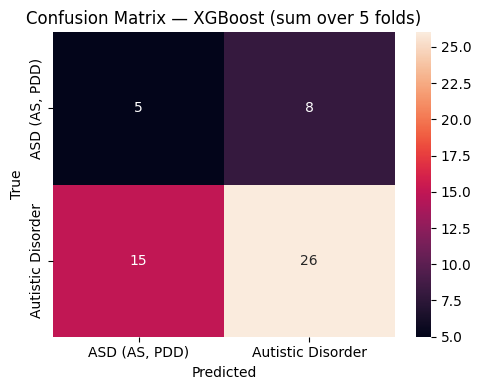

In [12]:
# std = sample standard deviation (ddof=1) over the N_FOLDS folds
def fmt(col, nd=4):
    return f"{cv_df[col].mean():.{nd}f} ± {cv_df[col].std(ddof=1):.{nd}f}"

print(f"XGBoost — {N_FOLDS}-fold CV (seed={SEED}) — mean ± std over folds\n")

print("=== PARTICIPANT level — classification ===")
print(f"Precision (%) : {fmt('precision', 2)}")
print(f"Recall    (%) : {fmt('recall', 2)}")
print(f"F1        (%) : {fmt('f1', 2)}")
print(f"Accuracy  (%) : {fmt('accuracy', 2)}")
print(f"AUC           : {fmt('auc')}")

print("\n=== IMAGE level (per chunk) — regression on P(class 1) ===")
print(f"MAE  : {fmt('mae_img')}")
print(f"MSE  : {fmt('mse_img')}")
print(f"RMSE : {fmt('rmse_img')}")
print(f"R2   : {fmt('r2_img')}")

print("\n=== PARTICIPANT level — regression on mean P(class 1) ===")
print(f"MAE  : {fmt('mae_part')}")
print(f"MSE  : {fmt('mse_part')}")
print(f"RMSE : {fmt('rmse_part')}")
print(f"R2   : {fmt('r2_part')}")

# Summary table (one row per metric)
cv_summary = pd.DataFrame({
    'mean': cv_df.drop(columns=['n_test_participants', 'n_test_images']).mean(),
    'std':  cv_df.drop(columns=['n_test_participants', 'n_test_images']).std(ddof=1),
}).round(4)
display(cv_summary)

# Confusion matrix cumulated over the 5 test folds (each participant is tested exactly once)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_total, annot=True, fmt="d", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title(f"Confusion Matrix — XGBoost (sum over {N_FOLDS} folds)")
plt.tight_layout(); plt.show()
